In [36]:
import numpy as np
import pandas as pd
import seaborn as sns
# Aynı sonuçları tekrar elde edebilmek için
np.random.seed(42)

# 500 öğrencilik veri seti oluşturuyoruz
n = 500

# Öğrencilerin günlük çalışma saatleri: 0-10 saat
calisma_saati = np.random.uniform(0, 10, n)

# Öğrencilerin devamsızlık günleri: 0-12 gün
devamsizlik_gun = np.random.uniform(0, 12, n)

# Başarıyı etkileyen doğrusal puanı oluşturuyoruz
logit = (
    -4
    + 0.85 * calisma_saati
    - 0.55 * devamsizlik_gun
)

# Doğrusal puanı 0-1 aralığında olasılığa dönüştürüyoruz
olasilik = 1 / (1 + np.exp(-logit))

# Olasılığa göre geçti (1) / kaldı (0) etiketlerini üretiyoruz
gecti = np.random.binomial(1, olasilik)

# Bütün değişkenleri DataFrame içerisinde birleştiriyoruz
df = pd.DataFrame({
    "Calisma_Saati": calisma_saati,
    "Devamsizlik_Gun": devamsizlik_gun,
    "Gecti": gecti
})



In [18]:
df

,Calisma_Saati,Devamsizlik_Gun,Gecti
0,3.745401,8.377941,0
1,9.507143,6.433156,1
2,7.319939,3.714331,0
3,5.986585,9.765540,0
4,1.560186,8.216774,0
...,...,...,...
495,3.533522,1.098985,0
496,5.836561,11.007763,0
497,0.777346,1.641824,0
498,9.743948,11.402848,0


In [21]:
df.head(10)

,Calisma_Saati,Devamsizlik_Gun,Gecti
0,3.745401,8.377941,0
1,9.507143,6.433156,1
2,7.319939,3.714331,0
3,5.986585,9.765540,0
4,1.560186,8.216774,0
5,1.559945,1.951403,0
6,0.580836,10.931126,0
7,8.661761,9.870447,0
8,6.011150,11.397599,0
9,7.080726,8.708634,0


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Calisma_Saati    500 non-null    float64
 1   Devamsizlik_Gun  500 non-null    float64
 2   Gecti            500 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 11.8 KB


In [23]:
df["Gecti"].value_counts()

Gecti
0    394
1    106
Name: count, dtype: int64

In [25]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Calisma_Saati,500.0,4.985617,2.986884,0.050616,2.412797,5.131637,7.561249,9.929648
Devamsizlik_Gun,500.0,5.783417,3.425921,0.055584,2.749191,5.661859,8.716042,11.996612
Gecti,500.0,0.212000,0.409134,0.000000,0.000000,0.000000,0.000000,1.000000


In [27]:
df.head()

,Calisma_Saati,Devamsizlik_Gun,Gecti
0,3.745401,8.377941,0
1,9.507143,6.433156,1
2,7.319939,3.714331,0
3,5.986585,9.765540,0
4,1.560186,8.216774,0


In [28]:
X=df.drop("Gecti",axis=1)

y=df["Gecti"]

In [29]:
print("X boyutu:",X.shape)
print("y boyutu:",y.shape)

X boyutu: (500, 2)
y boyutu: (500,)


In [30]:
import matplotlib.pyplot as plt

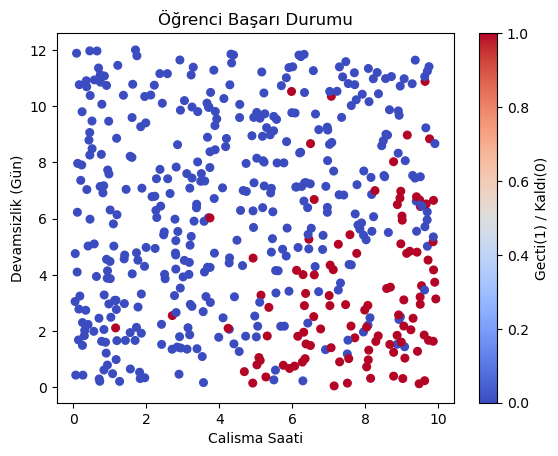

In [35]:
plt.scatter(
    df["Calisma_Saati"],
    df["Devamsizlik_Gun"],
    c=df["Gecti"],
    cmap="coolwarm",
    s=30
)
plt.xlabel("Calisma Saati")
plt.ylabel("Devamsizlik (Gün)")
plt.title("Öğrenci Başarı Durumu")
plt.colorbar(label="Gecti(1) / Kaldı(0)")
plt.show()

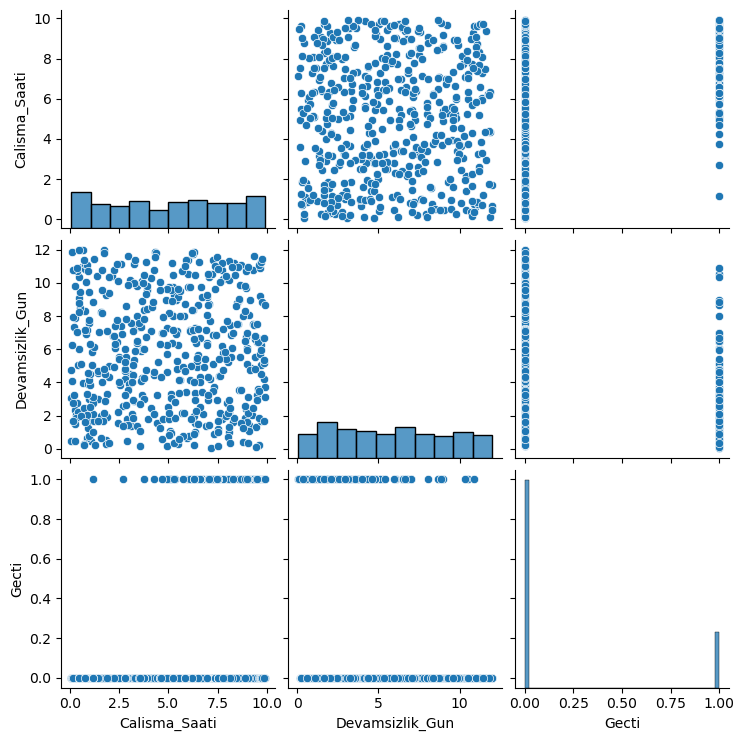

In [37]:
sns.pairplot(df)

In [38]:
from sklearn.model_selection import train_test_split

In [39]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [44]:
print("x_train",X_train.shape)
print("y_train:",y_train.shape)
print("Xtest",X_test.shape)
print("y_test:",y_test.shape)

x_train (400, 2)
y_train: (400,)
Xtest (100, 2)
y_test: (100,)


In [45]:
from sklearn.preprocessing import StandardScaler

In [46]:
scaler = StandardScaler()

In [47]:
X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [49]:
from sklearn.linear_model import LogisticRegression

In [50]:
model = LogisticRegression()

In [51]:
model.fit(X_train_scaled,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [52]:
from sklearn.metrics import (
accuracy_score,
confusion_matrix,
classification_report
)


In [53]:
y_pred = model.predict(X_test_scaled)

In [55]:
print("Accuaracy:",accuracy_score(y_test,y_pred))
print("\n Confusion Matrix:")
print(confusion_matrix(y_test,y_pred))
print("\n Classification Report")
print(classification_report(y_test,y_pred))

Accuaracy: 0.81

 Confusion Matrix:
[[71  8]
 [11 10]]

 Classification Report
              precision    recall  f1-score   support

           0       0.87      0.90      0.88        79
           1       0.56      0.48      0.51        21

    accuracy                           0.81       100
   macro avg       0.71      0.69      0.70       100
weighted avg       0.80      0.81      0.80       100



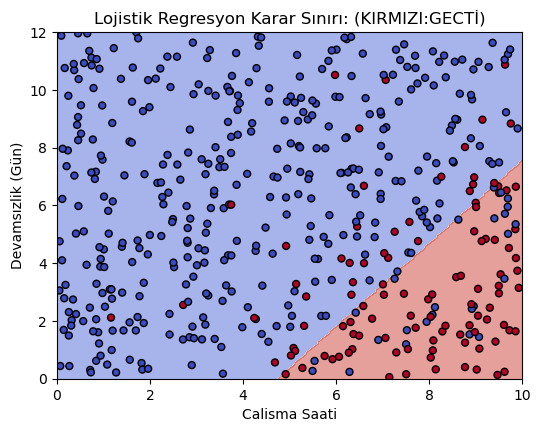

In [60]:
xx, yy = np.meshgrid(
    np.linspace(0, 10, 200),
    np.linspace(0, 12, 200)
)

grid = pd.DataFrame({
    "Calisma_Saati": xx.ravel(),
    "Devamsizlik_Gun": yy.ravel()
})

zz = model.predict(
    scaler.transform(grid)
).reshape(xx.shape)

plt.figure(figsize=(6, 4.5))

plt.contourf(
    xx,
    yy,
    zz,
    alpha=0.50,
    cmap="coolwarm"
)

plt.scatter(
    df["Calisma_Saati"],
    df["Devamsizlik_Gun"],
    c=df["Gecti"],
    cmap="coolwarm",
    edgecolors="k",
    s=25
)
plt.xlabel("Calisma Saati")
plt.ylabel("Devamsızlik (Gün)")
plt.title("Lojistik Regresyon Karar Sınırı: (KIRMIZI:GECTİ)")
plt.show()